# 02 · Baseline models

**Why a baseline?** A score means nothing alone. "MAE = 2,000 JOD" — is that good?
We need reference points:
1. **Dummy model**: always predicts the median price. Any real model *must* beat it.
2. **Linear Regression**: the simplest real model. Strong models in the next notebook must beat *this*.

**Rule:** everything here uses **5-fold cross-validation on the training set only**. The test set stays locked until the final evaluation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import make_pipeline

from jocars.cleaning import clean
from jocars.config import FIGURES, RANDOM_STATE, ROOT
from jocars.data import load_raw
from jocars.evaluate import cross_validate_model
from jocars.features import add_features, build_preprocessor, split_xy, train_test
from jocars.plotting import SEQ, SERIES, TEXT_2, jod, set_style

set_style()
df = add_features(clean(load_raw()))
train, test = train_test(df)          # test is NOT used in this notebook
X, y = split_xy(train)
print(f"train rows: {len(train):,}   features: {X.shape[1]}")

train rows: 7,093   features: 21


## 1 · Three baselines

A **Pipeline** glues preprocessing and model into one object. When cross-validation calls `fit`, the
imputer/encoder learn *only from the training folds* — that's how we avoid leakage automatically.

- `Ridge` = Linear Regression + a small penalty on large coefficients (**regularization**).
  With 300+ one-hot columns, plain linear regression can over-react to rare categories; Ridge calms it down.

In [2]:
models = {
    "Dummy (median)": DummyRegressor(strategy="median"),
    "Linear Regression": make_pipeline(build_preprocessor("linear"), LinearRegression()),
    "Ridge (alpha=1)": make_pipeline(build_preprocessor("linear"), Ridge(alpha=1.0)),
}
rows = []
for name, model in models.items():
    r = cross_validate_model(model, X, y, folds=5)
    rows.append({"model": name, **{f"{k}": v["mean"] for k, v in r.items()},
                 "r2_log_std": r["r2_log"]["std"]})
results = pd.DataFrame(rows).set_index("model")
results.style.format({"mae_jod": "{:,.0f}", "rmse_jod": "{:,.0f}", "mape": "{:.1%}",
                      "r2_log": "{:.3f}", "r2_log_std": "{:.3f}"})

,mae_jod,rmse_jod,mape,r2_log,r2_log_std
model,,,,,
Dummy (median),"8,441","14,378",104.1%,-0.014,0.004
Linear Regression,"3,464","8,412",31.8%,0.775,0.011
Ridge (alpha=1),"3,463","8,443",31.7%,0.776,0.011


In [3]:
(ROOT / "reports").mkdir(exist_ok=True)
results.to_csv(ROOT / "reports" / "baseline_results.csv")

## 2 · How to read these numbers

- **MAE (JOD):** on average, how many dinars the prediction is off.
- **MAPE:** the same error as a percentage of the price — fair for cheap and expensive cars alike.
- **RMSE (JOD):** squares errors before averaging, so a few big misses (luxury cars) push it up a lot.
  RMSE ≫ MAE means *some* predictions are very wrong.
- **R² (log scale):** 0 = no better than guessing the median; 1 = perfect.
- **± std across folds:** small = the score is stable, not luck of one split.

## 3 · Where does the linear model go wrong?

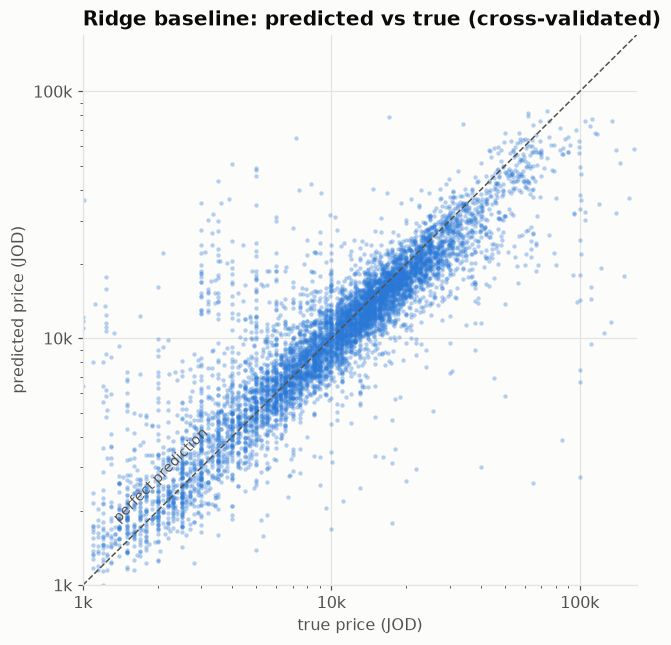

In [4]:
ridge = models["Ridge (alpha=1)"]
cv = KFold(5, shuffle=True, random_state=RANDOM_STATE)
pred_log = cross_val_predict(ridge, X, y, cv=cv)
true_jod, pred_jod = np.exp(y), np.exp(pred_log)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(true_jod, pred_jod, s=8, alpha=0.35, color=SEQ, linewidths=0)
lims = [1000, 170000]
ax.plot(lims, lims, color=TEXT_2, linewidth=1, linestyle="--")
ax.text(1300, 1800, "perfect prediction", color=TEXT_2, rotation=45, fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lims); ax.set_ylim(lims)
for a in (ax.xaxis, ax.yaxis):
    a.set_major_formatter(FuncFormatter(jod))
ax.set_xlabel("true price (JOD)"); ax.set_ylabel("predicted price (JOD)")
ax.set_title("Ridge baseline: predicted vs true (cross-validated)")
fig.savefig(FIGURES / "fig08_baseline_pred_vs_true.png"); plt.show()

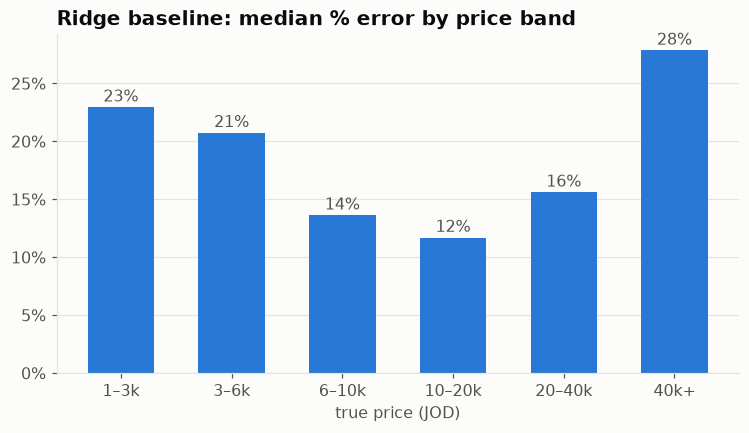

In [5]:
err = pd.DataFrame({"true": true_jod, "ape": np.abs(pred_jod - true_jod) / true_jod})
err["price band"] = pd.cut(err["true"], [1000, 3000, 6000, 10000, 20000, 40000, 200000],
                           labels=["1–3k", "3–6k", "6–10k", "10–20k", "20–40k", "40k+"])
band = err.groupby("price band", observed=True)["ape"].median()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(band.index.astype(str), band.values, color=SEQ, width=0.6)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="x", visible=False)
for i, v in enumerate(band.values):
    ax.text(i, v + 0.005, f"{v:.0%}", ha="center", color=TEXT_2)
ax.set_title("Ridge baseline: median % error by price band")
ax.set_xlabel("true price (JOD)")
fig.savefig(FIGURES / "fig09_baseline_error_by_band.png"); plt.show()

In [6]:
print(f"median % error: {err['ape'].median():.1%}   mean % error (MAPE): {err['ape'].mean():.1%}")
print(f"share of cars predicted within 20%: {(err['ape'] < 0.20).mean():.0%}")

median % error: 15.1%   mean % error (MAPE): 31.7%
share of cars predicted within 20%: 62%


**Reading the results:**
- The dummy model is off by **>100%** on average — that's the "know nothing" level.
- Ridge explains ~**78%** of the variation in log-price. A *typical* car (median) is predicted within ~15%,
  but the **mean** error (~32%) is pulled up by a few huge misses.
- Look at the scatter: points far above the diagonal at a true price of 1–5k are cars predicted at 10–40k.
  Some are genuinely hard (rare models), others are probably **listing noise** that survived cleaning
  (e.g. a down payment typed as the price for an older car). Real data is never perfectly clean —
  that's one reason we report the median error too.
- Errors are largest at both ends: cheap old cars (1–6k) and luxury cars (40k+), where data is thinner.

**Why linear models hit a ceiling here:**
- They assume each feature adds a *fixed* amount to log-price. But reality has **interactions**:
  one extra year costs a Land Rover far more dinars than a Kia; mileage matters more for petrol cars than for EVs.
- They can't learn "if brand = X **and** age > 10 **then** …" rules by themselves.

➡️ **Tree-based models** (Random Forest, XGBoost, LightGBM) learn exactly these if/then rules and interactions.
That's the next notebook.